# Post-Earnings Announcement Drift (PEAD) Analysis

This notebook demonstrates how to construct portfolios based on **Standardized Unexpected Earnings (SUE)** and analyze the **Post-Earnings Announcement Drift** phenomenon.

## Methodology

This analysis follows the methodology from **Livnat and Mendenhall (2006)** and focuses on **S&P 500 index constituents**.

## Overview

The PEAD strategy exploits the tendency of stock prices to continue drifting in the direction of an earnings surprise for several weeks following an earnings announcement. This program:

1. Extracts index constituents from Compustat
2. Gathers analyst earnings estimates from IBES
3. Adjusts estimates using CRSP adjustment factors
4. Calculates Standardized Unexpected Earnings (SUE)
5. Forms portfolios based on SUE rankings
6. Analyzes portfolio returns post-earnings announcement

## Prerequisites

This notebook requires:
- A pre-existing linking table between IBES and CRSP (created via ICLINK)
- Access to WRDS databases (CRSP, IBES, Compustat)
- Due to Python memory constraints, it's recommended to break large sample periods into batches

---

## Setup and Data Connection

In [1]:
#####################################
# Post Earnings Announcement Drift  #
# Qingyi (Freda) Song Drechsler     #
# Date: June 2019                   #
# Update: Jan 2021                  #
#####################################

# Update Note: this version uses CRSP data to extract S&P500 Index constituents,
# as comp.idxcst_hist data is no longer available on WRDS
# Also updated various .loc usage that has been deprecated by Python.
#
# Additional fixes (2025):
# - Fixed NA comparison issues in np.where() by using .eq().fillna(False)
# - Fixed FutureWarning for fillna downcasting by using .infer_objects(copy=False)
# - Reduced sample period to 2018-2022 for memory efficiency

import pandas as pd
import numpy as np
import wrds
import matplotlib.pyplot as plt
import pickle as pkl
from dateutil.relativedelta import *
import datetime

###################
# Connect to WRDS #
###################
conn=wrds.Connection(wrds_username='cpehlivanian')

# set sample date range
begdate = '01/01/2018'
enddate = '12/31/2022'

# set CRSP date range a bit wider to guarantee collecting all information
crsp_begdate = '01/01/2017'
crsp_enddate = '12/31/2023'

Loading library list...
Done


## Step 0: Load ICLINK Linking Table

We load the linking table between IBES and CRSP that was created by the ICLINK program. This table is essential for connecting analyst estimates (IBES) with stock returns data (CRSP).

In [2]:
#################################
# Step 0: Read in ICLINK output #
#################################

# iclink.pkl is the output from the python program iclink
# it contains the linking between crsp and ibes
with open('iclink.pkl', 'rb') as f:
    iclink = pkl.load(f)

## Step 1: Define the S&P 500 Index Universe

We identify all companies that were ever included in the S&P 500 index during our sample period. This involves:

1. Extracting S&P 500 constituents from CRSP's `msp500list` 
2. Linking Compustat GVKEY with IBES Tickers using ICLINK
3. For unmatched GVKEYs, using the header IBTIC link from Compustat Security file
4. Establishing date ranges for valid links between identifiers

**Note:** Earlier versions of this code used `comp.idxcst_his`, but this table is no longer available on WRDS.

In [3]:
##################################
# Step 1. S&P 500 Index Universe #
##################################

# All companies that were ever included in S&P 500 index as an example
# Old version of the code uses comp.idxcst_his

# New code uses crsp.msp500list
# Linking Compustat GVKEY and IBES Tickers using ICLINK               
# For unmatched GVKEYs, use header IBTIC link in Compustat Security file 


sp500 = conn.raw_sql(f"""
                        select a.*
                        from crsp.msp500list as a;
                        """, date_cols=['start', 'ending'])

# CCM data
_ccm = conn.raw_sql(""" select gvkey, lpermco as permco, lpermno as permno, 
                        linkdt, linkenddt 
                        from crsp.ccmxpf_linktable 
                        where usedflag=1 
                        and linkprim in ('P', 'C')""", date_cols=['linkdt', 'linkenddt'])

_ccm[['permco', 'permno']] = _ccm[['permco', 'permno']].astype(int)

# Fill linkenddt missing value (.E in SAS dataset) with today's date
_ccm['linkenddt'] = _ccm.linkenddt.fillna(datetime.date.today())

_sec = conn.raw_sql(""" select ibtic, gvkey from comp.security """)


# Start the sequence of left join
gvkey = pd.merge(sp500, _ccm, how='left', on=['permno'])
gvkey = pd.merge(gvkey, _sec.loc[_sec.ibtic.notna()], how='left', on=['gvkey'])

# high quality links from iclink
# score = 0 or 1
iclink_hq = iclink.loc[(iclink.score <=1)]

gvkey = pd.merge(gvkey, iclink_hq, how='left', on=['permno'])

# fill missing ticker with ibtic
gvkey.ticker = np.where(gvkey.ticker.notnull(), gvkey.ticker, gvkey.ibtic)

# Keep relevant columns and drop duplicates if there is any
gvkey = gvkey[['gvkey', 'permco', 'permno', 'linkdt', 'linkenddt','ticker']]

gvkey = gvkey.drop_duplicates()

# date ranges from gvkey
# min linkdt for ticker and permno combination
gvkey_mindt = gvkey.groupby(['ticker','permno']).linkdt.min().reset_index()

# max linkenddt for ticker and permno combination
gvkey['linkenddt'] = gvkey['linkenddt'].apply( lambda r: pd.Timestamp(r))
gvkey_maxdt = gvkey.groupby(['ticker','permno']).linkenddt.max().reset_index()

# link date range 
gvkey_dt = pd.merge(gvkey_mindt, gvkey_maxdt, how='inner', on=['ticker','permno'])

## Step 2: Extract Analyst Estimates from IBES

We extract earnings estimates from the IBES Unadjusted file and:

1. Select the **latest estimate** for each firm within a broker-analyst group
2. Focus on **quarterly forecasts** (fpi = 6 or 7) for the current and next fiscal quarter
3. Merge with our linking table to ensure proper date ranges

This gives us the raw analyst forecast data that we'll use to calculate earnings surprises.

In [4]:
#######################################
# Step 2. Extract Estimates from IBES #
#######################################

# Extract estimates from IBES Unadjusted file for a firm 
# within broker-analyst group "fpi in (6,7)" selects quarterly
# forecast for the current and the next fiscal quarter    

ibes_temp = conn.raw_sql(f"""
                        select ticker, estimator, analys, pdf, fpi, value, 
                        fpedats, revdats, revtims, anndats, anntims
                        from ibes.detu_epsus 
                        where fpedats between '{begdate}' and '{enddate}'
                        and (fpi='6' or fpi='7')
                        """, date_cols = ['revdats', 'anndats', 'fpedats'])


# merge to get date range linkdt and linkenddt to fulfill date requirement
ibes_temp = pd.merge(ibes_temp, gvkey_dt, how='left', on=['ticker'])
ibes_temp = ibes_temp.loc[(ibes_temp.linkdt<=ibes_temp.anndats) & (ibes_temp.anndats <= ibes_temp.linkenddt)]

In [5]:
ibes_temp.head(10)

,ticker,estimator,analys,pdf,fpi,value,fpedats,revdats,revtims,anndats,anntims,permno,linkdt,linkenddt
5621,003H,100.0,107687.0,D,6,0.9,2018-03-31,2018-02-07,06:17:53,2018-02-07,03:01:00,14579,2014-04-15,2026-10-18
5622,003H,183.0,170624.0,D,6,0.89,2018-03-31,2018-02-07,01:43:33,2018-02-07,01:37:00,14579,2014-04-15,2026-10-18
5623,003H,873.0,59239.0,D,6,0.89,2018-03-31,2018-02-07,00:58:30,2018-02-07,00:38:00,14579,2014-04-15,2026-10-18
5624,003H,2342.0,49027.0,D,6,0.98,2018-03-31,2018-02-07,08:49:27,2018-02-07,06:48:00,14579,2014-04-15,2026-10-18
5625,003H,98.0,123593.0,D,6,0.9,2018-03-31,2018-03-27,02:11:27,2018-02-07,05:10:00,14579,2014-04-15,2026-10-18
5626,003H,260.0,72445.0,D,6,0.88,2018-03-31,2018-04-26,17:22:39,2018-02-07,00:43:00,14579,2014-04-15,2026-10-18
5627,003H,3369.0,120428.0,D,6,0.9,2018-03-31,2018-05-01,13:22:14,2018-02-07,03:21:00,14579,2014-04-15,2026-10-18
5628,003H,282.0,130657.0,D,6,0.88,2018-03-31,2018-02-08,06:33:43,2018-02-07,08:23:00,14579,2014-04-15,2026-10-18
5629,003H,371.0,86075.0,D,6,0.88,2018-03-31,2018-02-08,04:27:20,2018-02-07,05:03:00,14579,2014-04-15,2026-10-18
5630,003H,954.0,165441.0,D,6,0.89,2018-03-31,2018-04-09,00:11:26,2018-02-07,07:01:00,14579,2014-04-15,2026-10-18


### Determine Dominant Reporting Basis

Following **Livnat and Mendenhall (2006)**, we determine whether most analysts report estimates on a **primary (P)** or **diluted (D)** basis for each security. 

We count the number of estimates reported on each basis and assign the dominant one. This ensures consistency when comparing estimates to actual earnings.

In [6]:
# Count number of estimates reported on primary/diluted basis 

p_sub = ibes_temp[['ticker','fpedats','pdf']].loc[ibes_temp.pdf=='P']
d_sub = ibes_temp[['ticker','fpedats','pdf']].loc[ibes_temp.pdf=='D']

p_count = p_sub.groupby(['ticker','fpedats']).pdf.count().reset_index().rename(columns={'pdf':'p_count'})
d_count = d_sub.groupby(['ticker','fpedats']).pdf.count().reset_index().rename(columns={'pdf':'d_count'})

ibes = pd.merge(ibes_temp, d_count, how = 'left', on=['ticker', 'fpedats'])
ibes = pd.merge(ibes, p_count, how='left', on =['ticker','fpedats'])
ibes['d_count'] = ibes.d_count.fillna(0)
ibes['p_count'] = ibes.p_count.fillna(0)

# Determine whether most analysts report estimates on primary/diluted basis
# following Livnat and Mendenhall (2006)                                   

ibes['basis']=np.where(ibes.p_count>ibes.d_count, 'P', 'D')

ibes = ibes.sort_values(by=['ticker','fpedats','estimator','analys','anndats', 'anntims', 'revdats', 'revtims'])\
.drop(['linkdt', 'linkenddt','p_count','d_count', 'pdf', 'fpi'], axis=1)

# Keep the latest observation for a given analyst
# Group by company fpedats estimator analys then pick the last record in the group

ibes_1 = ibes.groupby(['ticker','fpedats','estimator','analys']).apply(lambda x: x.index[-1], include_groups=False).to_frame().reset_index()

# reset index to the old dataframe index for join in the next step
ibes_1=ibes_1.set_index(0)

# Inner join with the last analyst record per group
ibes = pd.merge(ibes, ibes_1[['analys']], left_index=True, right_index=True)

# drop duplicate column
ibes=ibes.drop(['analys_y'], axis=1).rename(columns={'analys_x': 'analys'})

## Step 3: Link Analyst Forecasts with Actual Earnings

We now link the unadjusted estimates with unadjusted actual earnings from IBES and:

1. Extract actual quarterly earnings from `ibes.actu_epsus`
2. Keep only estimates issued **within 90 days** before the earnings report date
3. Merge estimates with actuals based on ticker and fiscal period end date

This step ensures we're only using recent, relevant forecasts when calculating earnings surprises.

In [7]:
#######################################
# Step 3. Link Estimates with Actuals #
#######################################

# Link Unadjusted estimates with Unadjusted actuals and CRSP permnos  
# Keep only the estimates issued within 90 days before the report date

# Getting actual piece of data
ibes_act = conn.raw_sql(f"""
                        select ticker, anndats as repdats, value as act, pends as fpedats, pdicity
                        from ibes.actu_epsus 
                        where pends between '{begdate}' and '{enddate}'
                        and pdicity='QTR'
                        """, date_cols = ['repdats', 'fpedats'])


# Join with the estimate piece of the data

ibes1 = pd.merge(ibes, ibes_act, how='left', on = ['ticker','fpedats'])
ibes1['dgap'] = ibes1.repdats - ibes1.anndats

ibes1['flag'] = np.where( (ibes1.dgap>=datetime.timedelta(days=0)) & (ibes1.dgap<=datetime.timedelta(days=90)) & (ibes1.repdats.notna()) & (ibes1.anndats.notna()), 1, 0)

ibes1 = ibes1.loc[ibes1.flag==1].drop(['flag', 'dgap', 'pdicity'], axis=1)

# Select all relevant combinations of Permnos and Date}

ibes1_dt1 = ibes1[['permno', 'anndats']].drop_duplicates()

ibes1_dt2 = ibes1[['permno', 'repdats']].drop_duplicates().rename(columns={'repdats':'anndats'})

ibes_anndats = pd.concat([ibes1_dt1, ibes1_dt2]).drop_duplicates()


In [8]:
ibes1.head(10)

,ticker,estimator,analys,value,fpedats,revdats,revtims,anndats,anntims,permno,basis,repdats,act
0,003H,98.0,123593.0,0.9,2018-03-31,2018-03-27,02:11:27,2018-02-07,05:10:00,14579,D,2018-05-01,0.95
1,003H,100.0,107687.0,0.9,2018-03-31,2018-02-07,06:17:53,2018-02-07,03:01:00,14579,D,2018-05-01,0.95
2,003H,171.0,54752.0,0.9,2018-03-31,2018-03-12,23:48:42,2018-02-12,23:46:00,14579,D,2018-05-01,0.95
3,003H,183.0,170624.0,0.89,2018-03-31,2018-02-07,01:43:33,2018-02-07,01:37:00,14579,D,2018-05-01,0.95
4,003H,260.0,72445.0,0.88,2018-03-31,2018-04-26,17:22:39,2018-02-07,00:43:00,14579,D,2018-05-01,0.95
5,003H,282.0,130657.0,0.88,2018-03-31,2018-02-08,06:33:43,2018-02-07,08:23:00,14579,D,2018-05-01,0.95
6,003H,371.0,86075.0,0.88,2018-03-31,2018-02-08,04:27:20,2018-02-07,05:03:00,14579,D,2018-05-01,0.95
7,003H,873.0,59239.0,0.89,2018-03-31,2018-02-07,00:58:30,2018-02-07,00:38:00,14579,D,2018-05-01,0.95
8,003H,954.0,165441.0,0.89,2018-03-31,2018-04-09,00:11:26,2018-02-07,07:01:00,14579,D,2018-05-01,0.95
9,003H,1267.0,47331.0,0.89,2018-03-31,2018-04-26,20:53:55,2018-02-07,00:52:00,14579,D,2018-05-01,0.95


### Adjust Dates to CRSP Trading Dates

We adjust all estimate and earnings announcement dates to the **closest preceding trading date** in CRSP. This is crucial because:

1. IBES dates may fall on non-trading days (weekends, holidays)
2. We need valid CRSP adjustment factors for all dates
3. This ensures proper alignment when merging with stock return data

We check up to 5 days prior to find the most recent trading date.

In [9]:
# Adjust all estimate and earnings announcement dates to the closest
# preceding trading date in CRSP to ensure that adjustment factors won't
# be missing after the merge  

# unique anndats from ibes
uniq_anndats = ibes_anndats[['anndats']].drop_duplicates()

# unique trade dates from crsp.dsi
crsp_dats = conn.raw_sql(""" 
                            select date 
                            from crsp.dsi 
                         """, date_cols=['date'])

# Create up to 5 days prior dates relative to anndats

for i in range(0, 5):
    uniq_anndats[i] = uniq_anndats.anndats - datetime.timedelta(days=i)

# reshape (transpose) the df for later join with crsp trading dates

expand_anndats = uniq_anndats.set_index('anndats').stack().reset_index().\
rename(columns={'level_1':'prior', 0:'prior_date'})

# merge with crsp trading dates
tradedates = pd.merge(expand_anndats, crsp_dats, how='left', left_on=['prior_date'], right_on=['date'])

# create the dgap (days gap) variable for min selection
tradedates['dgap'] = tradedates.anndats-tradedates.date

# choosing the row with the smallest dgap for a given anndats
tradedates = tradedates.loc[tradedates.groupby('anndats')['dgap'].idxmin()]

tradedates = tradedates[['anndats', 'date']]

### Merge CRSP Adjustment Factors

We extract CRSP cumulative adjustment factors (`cfacshr`) for both:
- Announcement dates (when forecasts are made)
- Report dates (when actual earnings are announced)

These factors account for stock splits, dividends, and other corporate actions.

In [10]:
# merge the CRSP adjustment factors for all estimate and report dates

# extract CRSP adjustment factors
cfacshr = conn.raw_sql(f"""
                        select permno, date, cfacshr
                        from crsp.dsf
                        where date between '{crsp_begdate}' and '{crsp_enddate}'
                        """, date_cols = ['date'])

ibes_anndats = pd.merge(ibes_anndats, tradedates, how='left', on = ['anndats'])

ibes_anndats = pd.merge(ibes_anndats, cfacshr, how='left', on=['permno', 'date'])

## Step 4: Adjust Estimates Using CRSP Adjustment Factors

We put estimates on the **same per-share basis** as company-reported EPS using CRSP adjustment factors. 

The formula is:
```
new_value = (cfacshr_rep / cfacshr_ann) * original_estimate
```

This adjustment ensures that:
- Stock splits and dividends are properly accounted for
- Forecasts and actuals are comparable
- The earnings surprise calculation is accurate

After adjustment, we verify that each firm-fiscal period has only one estimate per analyst.

In [11]:
#########################################
# Step 4. Adjust Estimates with CFACSHR #
#########################################

# Put the estimate on the same per share basis as
# company reported EPS using CRSP Adjustment factors. 
# New_value is the estimate adjusted to be on the 
# same basis with reported earnings.

ibes1 = pd.merge(ibes1, ibes_anndats, how='inner', on=['permno', 'anndats'])
ibes1 = ibes1.drop(['anndats','date'], axis=1).rename(columns={'cfacshr':'cfacshr_ann'})

ibes1 = pd.merge(ibes1, ibes_anndats, how='inner', left_on=['permno', 'repdats'], right_on=['permno','anndats'])
ibes1 = ibes1.drop(['anndats','date'], axis=1).rename(columns={'cfacshr':'cfacshr_rep'})

ibes1['new_value'] = (ibes1.cfacshr_rep/ibes1.cfacshr_ann)*ibes1.value

# Sanity check: there should be one most recent estimate for 
# a given firm-fiscal period end combination 
ibes1 = ibes1.sort_values(by=['ticker','fpedats','estimator','analys']).drop_duplicates()

### Calculate Median Forecast

We compute the **median forecast** based on all estimates made in the 90 days prior to the earnings announcement date (EAD).

Using the median (rather than mean) helps reduce the impact of outlier forecasts and provides a more robust consensus estimate.

In [12]:
# Compute the median forecast based on estimates in the 90 days prior to the EAD

grp_permno = ibes1.groupby(['ticker','fpedats', 'basis','repdats', 'act']).permno.max().reset_index()

medest = ibes1.groupby(['ticker','fpedats', 'basis','repdats', 'act']).new_value.agg(['median','count']).reset_index()
medest = pd.merge(medest, grp_permno, how='inner', on=['ticker','fpedats','basis', 'repdats', 'act'])
medest = medest.rename(columns={'median': 'medest', 'count':'numest'})

## Step 5: Merge with Compustat Fundamental Data

We extract fundamental data from Compustat's quarterly file (`comp.fundq`) including:

- Quarterly EPS (primary and diluted basis)
- Price and shares outstanding
- Market capitalization
- Total assets and sales
- Report dates and fiscal period information

We then merge this with our IBES median estimates, matching on:
- Ticker
- Fiscal period end date (datadate in Compustat = fpedats in IBES)

This creates our master dataset combining accounting data, analyst forecasts, and actual earnings.

In [13]:
######################################
# Step 5. Merge with Compustat Data  #
######################################

# get items from fundq
fundq = conn.raw_sql(f"""
                        select gvkey, fyearq, fqtr, conm, datadate, rdq, epsfxq, epspxq, cshoq, prccq, 
                        ajexq, spiq, cshoq, cshprq, cshfdq, saleq, atq, fyr, datafqtr, cshoq*prccq as mcap  
                        from comp.fundq 
                        where consol='C' and popsrc='D' and indfmt='INDL' and datafmt='STD'
                        and datadate between '{crsp_begdate}' and '{crsp_enddate}' 
                        """, date_cols = ['datadate', 'datafqtr', 'rdq'])

fundq = fundq.loc[((fundq.atq>0) | (fundq.saleq.notna())) & (fundq.datafqtr.notna())]


# Calculate link date ranges for givken gvkey and ticker combination

gvkey_mindt1 = gvkey.groupby(['gvkey', 'ticker']).linkdt.min().reset_index().rename(columns={'linkdt':'mindate'})
gvkey_maxdt1 = gvkey.groupby(['gvkey', 'ticker']).linkenddt.max().reset_index().rename(columns={'linkenddt':'maxdate'})
gvkey_dt1 = pd.merge(gvkey_mindt1, gvkey_maxdt1, how='inner', on=['gvkey','ticker'])


# Use the date range to merge
comp = pd.merge(fundq, gvkey_dt1, how='left', on =['gvkey'])
comp = comp.loc[(comp.ticker.notna()) & (comp.datadate<=comp.maxdate) & (comp.datadate>=comp.mindate)]

# Merge with the median esitmates
comp = pd.merge(comp, medest, how = 'left', left_on=['ticker','datadate'], right_on=['ticker', 'fpedats'])

# Sort data and drop duplicates
comp = comp.sort_values(by=['gvkey','fqtr','fyearq']).drop_duplicates()

/home/charles/.local/lib/python3.10/site-packages/wrds/sql.py:603: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  for chunk in df:


## Step 6: Calculate Standardized Unexpected Earnings (SUE)

We calculate three different measures of earnings surprises:

### SUE1 and SUE2: Historical Comparison
These measures compare current quarter earnings to the **same quarter in the prior year**:

**SUE1:**
```
SUE1 = (Actual EPS - Expected EPS from prior year) / Price
```

**SUE2:** 
Similar to SUE1 but adjusts for special items (65% of special items per share)

### SUE3: Analyst-Based (Primary Measure)
This is our main measure, comparing actual earnings to analyst consensus:

**SUE3:**
```
SUE3 = (Actual EPS - Median Analyst Forecast) / Price
```

All measures are **standardized by stock price** to make them comparable across firms.

### Key Steps:
1. Extract lagged EPS and adjustment factors (for same quarter, prior year)
2. Handle reporting basis (Primary vs. Diluted)
3. Adjust for special items where appropriate
4. Calculate all three SUE measures
5. Define the earnings announcement date (EAD) as the next trading day after report date
6. Define the following EAD as `leadrdq1`

In [14]:
###########################
# Step 6. Calculate SUEs  #
###########################

# block handling lag eps

sue = comp.sort_values(by=['gvkey','fqtr','fyearq'])

sue['dif_fyearq'] = sue.groupby(['gvkey', 'fqtr']).fyearq.diff()
sue['laggvkey']   = sue.gvkey.shift(1)

# handling same qtr previous year

cond_year = sue.dif_fyearq==1 # year increment is 1
cond_year = cond_year.fillna(False)

sue['lagadj']     = np.where(cond_year, sue.ajexq.shift(1), None)
sue['lageps_p']   = np.where(cond_year, sue.epspxq.shift(1), None)
sue['lageps_d']   = np.where(cond_year, sue.epsfxq.shift(1), None)
sue['lagshr_p']   = np.where(cond_year, sue.cshprq.shift(1), None)
sue['lagshr_d']   = np.where(cond_year, sue.cshfdq.shift(1), None)
sue['lagspiq']    = np.where(cond_year, sue.spiq.shift(1), None)

# handling first gvkey

cond_gvkey = sue.gvkey != sue.laggvkey # first.gvkey
cond_gvkey = cond_gvkey.fillna(False)

sue['lagadj']     = np.where(cond_gvkey, None, sue.lagadj)
sue['lageps_p']   = np.where(cond_gvkey, None, sue.lageps_p)
sue['lageps_d']   = np.where(cond_gvkey, None, sue.lageps_d)
sue['lagshr_p']   = np.where(cond_gvkey, None, sue.lagshr_p)
sue['lagshr_d']   = np.where(cond_gvkey, None, sue.lagshr_d)
sue['lagspiq']    = np.where(cond_gvkey, None, sue.lagspiq)


# handling reporting basis 

# Basis = P and missing are treated the same

sue['actual1'] = np.where(sue.basis=='D', sue.epsfxq/sue.ajexq, sue.epspxq/sue.ajexq)

sue['actual2'] = np.where(sue.basis=='D', \
                            ((sue.epsfxq.fillna(0)-(0.65*sue.spiq/sue.cshfdq).fillna(0))/sue.ajexq).infer_objects(copy=False), \
                            ((sue.epspxq.fillna(0)-(0.65*sue.spiq/sue.cshprq).fillna(0))/sue.ajexq).infer_objects(copy=False)
                           )

sue['expected1'] = np.where(sue.basis=='D', sue.lageps_d/sue.lagadj, sue.lageps_p/sue.lagadj)
sue['expected2'] = np.where(sue.basis=='D', \
                              ((sue.lageps_d.fillna(0)-(0.65*sue.lagspiq/sue.lagshr_d).fillna(0))/sue.lagadj).infer_objects(copy=False), \
                              ((sue.lageps_p.fillna(0)-(0.65*sue.lagspiq/sue.lagshr_p).fillna(0))/sue.lagadj).infer_objects(copy=False)
                             )

# SUE calculations
sue['sue1'] = (sue.actual1 - sue.expected1) / (sue.prccq/sue.ajexq)
sue['sue2'] = (sue.actual2 - sue.expected2) / (sue.prccq/sue.ajexq)
sue['sue3'] = (sue.act - sue.medest) / sue.prccq

sue = sue[['ticker','permno','gvkey','conm','fyearq','fqtr','fyr','datadate','repdats','rdq', \
           'sue1','sue2','sue3','basis','act','medest','numest','prccq','mcap']]

# Shifting the announcement date to be the next trading day
# Defining the day after the following quarterly EA as leadrdq1

# unique rdq 
uniq_rdq = comp[['rdq']].drop_duplicates()

# Create up to 5 days post rdq relative to rdq
for i in range(0, 5):
    uniq_rdq[i] = uniq_rdq.rdq + datetime.timedelta(days=i)

# reshape (transpose) for later join with crsp trading dates
expand_rdq = uniq_rdq.set_index('rdq').stack().reset_index().\
rename(columns={'level_1':'post', 0:'post_date'})

# merge with crsp trading dates
eads1 = pd.merge(expand_rdq, crsp_dats, how='left', left_on=['post_date'], right_on=['date'])

# create the dgap (days gap) variable for min selection
eads1['dgap'] = eads1.date-eads1.rdq

# LOC deprecated, use reindex instead
#eads1 = eads1.loc[eads1.groupby('rdq')['dgap'].idxmin()].rename(columns={'date':'rdq1'})
eads1 = eads1.reindex(eads1.groupby('rdq')['dgap'].idxmin()).rename(columns={'date':'rdq1'})

# create sue_final
sue_final = pd.merge(sue, eads1[['rdq','rdq1']], how='left', on=['rdq'])
sue_final = sue_final.sort_values(by=['gvkey', 'fyearq','fqtr'], ascending=[True, False, False]).drop_duplicates()


/tmp/ipykernel_1281908/2631269805.py:50: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ((sue.lageps_d.fillna(0)-(0.65*sue.lagspiq/sue.lagshr_d).fillna(0))/sue.lagadj).infer_objects(copy=False), \
/tmp/ipykernel_1281908/2631269805.py:51: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ((sue.lageps_p.fillna(0)-(0.65*sue.lagspiq/sue.lagshr_p).fillna(0))/sue.lagadj).infer_objects(copy=False)


In [15]:
sue_final.head(10)

,ticker,permno,gvkey,conm,fyearq,fqtr,fyr,datadate,repdats,rdq,sue1,sue2,sue3,basis,act,medest,numest,prccq,mcap,rdq1
27,AMR,<NA>,001045,AMERICAN AIRLINES GROUP INC,2023,4,12,2023-12-31,NaT,2024-01-25,-0.087336,-0.072527,<NA>,NaN,<NA>,<NA>,<NA>,13.74,8989.71102,2024-01-25
20,AMR,<NA>,001045,AMERICAN AIRLINES GROUP INC,2023,3,12,2023-09-30,NaT,2023-10-19,-0.12256,-0.048573,<NA>,NaN,<NA>,<NA>,<NA>,12.81,8371.38624,2023-10-19
13,AMR,<NA>,001045,AMERICAN AIRLINES GROUP INC,2023,2,12,2023-06-30,NaT,2023-07-20,0.073579,0.075243,<NA>,NaN,<NA>,<NA>,<NA>,17.94,11719.96878,2023-07-20
6,AMR,<NA>,001045,AMERICAN AIRLINES GROUP INC,2023,1,12,2023-03-31,NaT,2023-04-27,0.172203,0.163308,<NA>,NaN,<NA>,<NA>,<NA>,14.75,9629.0655,2023-04-27
26,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2022,4,12,2022-12-31,2023-01-26,2023-01-26,0.20283,0.204898,0.002358,D,1.17,1.14,12,12.72,8276.16624,2023-01-26
19,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2022,3,12,2022-09-30,2022-10-20,2022-10-20,0.036545,0.118541,0.003322,D,0.69,0.65,11,12.04,7824.35052,2022-10-20
12,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2022,2,12,2022-06-30,2022-07-21,2022-07-21,0.051262,0.164461,0.001972,D,0.76,0.735,12,12.68,8239.19772,2022-07-21
5,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2022,1,12,2022-03-31,2022-04-21,2022-04-21,-0.030137,0.085048,0.004384,D,-2.32,-2.4,11,18.25,11853.3385,2022-04-21
25,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2021,4,12,2021-12-31,2022-01-20,2022-01-20,0.13196,0.1309,0.001114,D,-1.42,-1.44,12,17.96,11633.19488,2022-01-20
18,AMR,21020,001045,AMERICAN AIRLINES GROUP INC,2021,3,12,2021-09-30,2021-10-21,2021-10-21,0.241715,0.227626,0.000487,D,-0.99,-1.0,12,20.52,13286.22804,2021-10-21


### Apply Sample Filters

Following **Livnat & Mendenhall (2006)**, we apply the following filters:

1. **Earnings announcement date** is reported in Compustat
2. **Price per share** is available at fiscal quarter end
3. **Price > 1** to avoid issues with low-priced stocks
4. **Market capitalization > $5 million** to ensure adequate liquidity
5. **EADs in Compustat and IBES** should not differ by more than 1 calendar day
6. Valid book equity available

We also ensure that:
- The next consecutive EAD (`leadrdq1`) is defined
- There's sufficient time between consecutive EADs (> 30 days)

These filters ensure we have high-quality data for portfolio formation and analysis.

In [16]:
#  Filter from Livnat & Mendenhall (2006):                                
#- earnings announcement date is reported in Compustat                   
#- the price per share is available from Compustat at fiscal quarter end  
#- price is greater than $1                                              
#- the market (book) equity at fiscal quarter end is available and is    
# EADs in Compustat and in IBES (if available)should not differ by more  
# than one calendar day larger than $5 mil.                              

sue_final['leadrdq1'] = sue_final.rdq1.shift(1) # next consecutive EAD
sue_final['leadgvkey'] = sue_final.gvkey.shift(1)

# If first gvkey then leadrdq1 = rdq1+3 months
# Else leadrdq1 = previous rdq1

sue_final['leadrdq1'] = np.where(sue_final.gvkey.eq(sue_final.leadgvkey).fillna(False), 
                                  sue_final.rdq1.shift(1), 
                                  sue_final.rdq1 + pd.DateOffset(months=3))


#sue_final['dgap'] = (sue_final.repdats - sue_final.rdq).fillna(0)
sue_final['dgap'] = (sue_final.repdats - sue_final.rdq).fillna(pd.Timedelta(days=0))
sue_final = sue_final.loc[(sue_final.rdq1 != sue_final.leadrdq1)]

# Various conditioning for filtering
cond1 = (sue_final.sue1.notna()) & (sue_final.sue2.notna()) & (sue_final.repdats.isna())
cond2 = (sue_final.repdats.notna()) & (sue_final.dgap<=datetime.timedelta(days=1)) & (sue_final.dgap>=datetime.timedelta(days=-1))
sue_final = sue_final.loc[cond1 | cond2]

# Impose restriction on price and marketcap
sue_final = sue_final.loc[(sue_final.rdq.notna()) & (sue_final.prccq>1) & (sue_final.mcap>5)]

# Keep relevant columns
sue_final = sue_final[['gvkey', 'ticker','permno','conm', 'dgap',\
                       'fyearq','fqtr','datadate','fyr','rdq','rdq1','leadrdq1','repdats',\
                       'mcap','medest','act','numest','basis','sue1','sue2','sue3']]

## Step 7: Form Portfolios Based on SUE

Now we form portfolios to test the Post-Earnings Announcement Drift hypothesis.

### Process:

1. **Extract daily returns** from CRSP around and between earnings announcement dates
2. **Calculate excess returns** (stock return minus market return)
3. **Link returns to SUE measures** for each stock-quarter

We focus on the period from:
- **Start:** 1 day after the earnings announcement (`rdq1`)
- **End:** The day of the next quarterly earnings announcement (`leadrdq1`)

This is the window where the "drift" is expected to occur - stocks with positive (negative) earnings surprises should continue to outperform (underperform).

In [17]:
#########################################
# Step 7. Form Portfolios Based on SUE  #
#########################################

# Extract file of raw daily returns around and between EADs and link them 
# to Standardized Earnings Surprises for forming SUE-based portfolios     

# Records from dsf and dsi to calculate exret
dsf = conn.raw_sql(f"""
                        select permno, date, prc, abs(prc*shrout) as mcap, ret from crsp.dsf
                        where date between '{crsp_begdate}' and '{crsp_enddate}'
                        """, date_cols = ['date'])

dsi = conn.raw_sql(f"""
                    select date, vwretd from crsp.dsi where date between '{crsp_begdate}' and '{crsp_enddate}'
                    """, date_cols=['date'])

ds = pd.merge(dsf, dsi, how='left', on=['date'])
ds['exret'] = ds.ret - ds.vwretd
ds = ds.rename(columns={'vwretd':'mkt'})

# Records from sue_final that meet the condition
sue_final_join = sue_final.loc[(sue_final.rdq.notna()) & (sue_final.leadrdq1.notna()) & (sue_final.permno.notna()) \
                               & (sue_final.leadrdq1-sue_final.rdq1>datetime.timedelta(days=30))]
sue_final_join1 = sue_final_join.copy()

sue_final_join1['lb_date'] = sue_final_join.rdq1-datetime.timedelta(days=5)
sue_final_join1['ub_date'] = sue_final_join.leadrdq1+datetime.timedelta(days=5)


sfj_indexed = sue_final_join1[['permno','rdq1', 'leadrdq1','sue1','sue2','sue3', 'lb_date','ub_date']].set_index('permno')
crsprets = ds.join(sfj_indexed, how='left', on='permno')
crsprets = crsprets.loc[(crsprets.date<=crsprets.ub_date) & (crsprets.date>=crsprets.lb_date)]
crsprets = crsprets.drop(['lb_date','ub_date'], axis=1)

### Estimate the Drift

We sum daily returns over the drift period to calculate cumulative abnormal returns.

**Key steps:**
1. Filter returns to the drift window (from `rdq1` to `leadrdq1`)
2. Use lagged market cap for weighting (to avoid look-ahead bias)
3. Create event time counter (`ncount`) starting from the EAD

In [18]:
# To estimate the drift, sum daily returns over the period from  
# 1 day after the earnings announcement through the day of       
# the following quarterly earnings announcement       

temp = crsprets.sort_values(by=['permno', 'rdq1', 'date'])
temp['lpermno'] = temp.permno.shift(1)

# If first permno then lagmcap = missing 
# Else lagmcap = lag(mcap)
temp['lagmcap'] = np.where(temp.permno.eq(temp.lpermno).fillna(False), 
                                  temp.mcap.shift(1), 
                                  None)

temp = temp.loc[(temp.rdq1<=temp.date) & (temp.date<=temp.leadrdq1)]

# create count variable within the group
temp['ncount'] = temp.groupby(['permno','rdq1']).cumcount()

### Form SUE-Based Portfolios

We now sort stocks into **quintiles** based on their SUE values:

1. **Portfolio 1 (sue3r=0):** Most negative earnings surprises
2. **Portfolio 2 (sue3r=1):** Below median negative surprises
3. **Portfolio 3 (sue3r=2):** Neutral
4. **Portfolio 4 (sue3r=3):** Above median positive surprises  
5. **Portfolio 5 (sue3r=4):** Most positive earnings surprises

For this analysis, we use **SUE3** (analyst-based measure) as our primary sorting variable.

### Portfolio Returns

We calculate **value-weighted excess returns** for each portfolio:
- Weights are based on lagged market capitalization
- Returns are cumulated over event time (days since EAD)
- We track performance for the first 50 days after the earnings announcement

**Expected Result:** Portfolio 5 (most positive SUE) should drift upward, while Portfolio 1 (most negative SUE) should drift downward, demonstrating the PEAD phenomenon.

In [20]:

# Form quintiles based on SUE
peadrets = temp.sort_values(by=['ncount','permno','rdq1']).drop_duplicates()

peadrets['sue1r']=peadrets.groupby('ncount')['sue1'].transform(lambda x: pd.qcut(x, 5, labels=False, duplicates='drop'))
peadrets['sue2r']=peadrets.groupby('ncount')['sue2'].transform(lambda x: pd.qcut(x, 5, labels=False, duplicates='drop'))
peadrets['sue3r']=peadrets.groupby('ncount')['sue3'].transform(lambda x: pd.qcut(x, 5, labels=False, duplicates='drop'))

# Form portfolios on Compustat-based SUEs (=sue1 or =sue2) or IBES-based SUE (=sue3)
# Code uses sue3

peadrets3 = peadrets.loc[peadrets.sue3r.notna()].sort_values(by=['ncount', 'sue3'])
peadrets3['sue3r'] = peadrets3['sue3r'].astype(int)

# Form value-weighted exret
# Calculate group weight sum;
grp_lagmcap = peadrets3.groupby(['ncount','sue3r']).lagmcap.sum().reset_index().rename(columns={'lagmcap':'total_lagmcap'})

# join group weight sum back to the df
peadrets3 = pd.merge(peadrets3, grp_lagmcap, how='left', on=['ncount','sue3r'])

# vw exret
peadrets3 = peadrets3.loc[peadrets3.total_lagmcap > 0]

peadrets3['wt_exret'] = peadrets3.exret * peadrets3.lagmcap / peadrets3.total_lagmcap
peadsue3port = peadrets3.groupby(['ncount', 'sue3r']).wt_exret.sum().reset_index()


# set ncount=0 all five portfolio weighted returns to be 0
peadsue3port['wt_exret'] = np.where(peadsue3port.ncount==0, 0, peadsue3port.wt_exret)

# transpose table for cumulative return calculation
peadsue3port = peadsue3port.pivot_table(index=['ncount'], columns='sue3r')

# reset column index level
peadsue3port.columns = [col[1] for col in peadsue3port.columns]
peadsue3port = peadsue3port.reset_index()

# keep only first 50 days after EADs
peadsue3port = peadsue3port.loc[peadsue3port.ncount<=50]

# Cumulating Excess Returns

peadsue3port['sueport1'] = peadsue3port[0].cumsum()
peadsue3port['sueport2'] = peadsue3port[1].cumsum()
peadsue3port['sueport3'] = peadsue3port[2].cumsum()
peadsue3port['sueport4'] = peadsue3port[3].cumsum()
peadsue3port['sueport5'] = peadsue3port[4].cumsum()

## Visualization: Cumulative Abnormal Returns (CARs)

We plot the cumulative excess returns for all five SUE portfolios over the 50 days following earnings announcements.

**Interpretation:**
- The **y-axis** shows cumulative value-weighted excess returns
- The **x-axis** shows event time (t=0 is the earnings announcement date)
- **Portfolio 5 (orchid line):** Stocks with the most positive earnings surprises
- **Portfolio 1 (skyblue line):** Stocks with the most negative earnings surprises

If PEAD exists, we should observe:
- Portfolio 5 trending **upward** (positive drift)
- Portfolio 1 trending **downward** (negative drift)
- The spread widening over time, demonstrating continued market reaction to earnings news

Plot saved to ./plot/pead_08_18.png


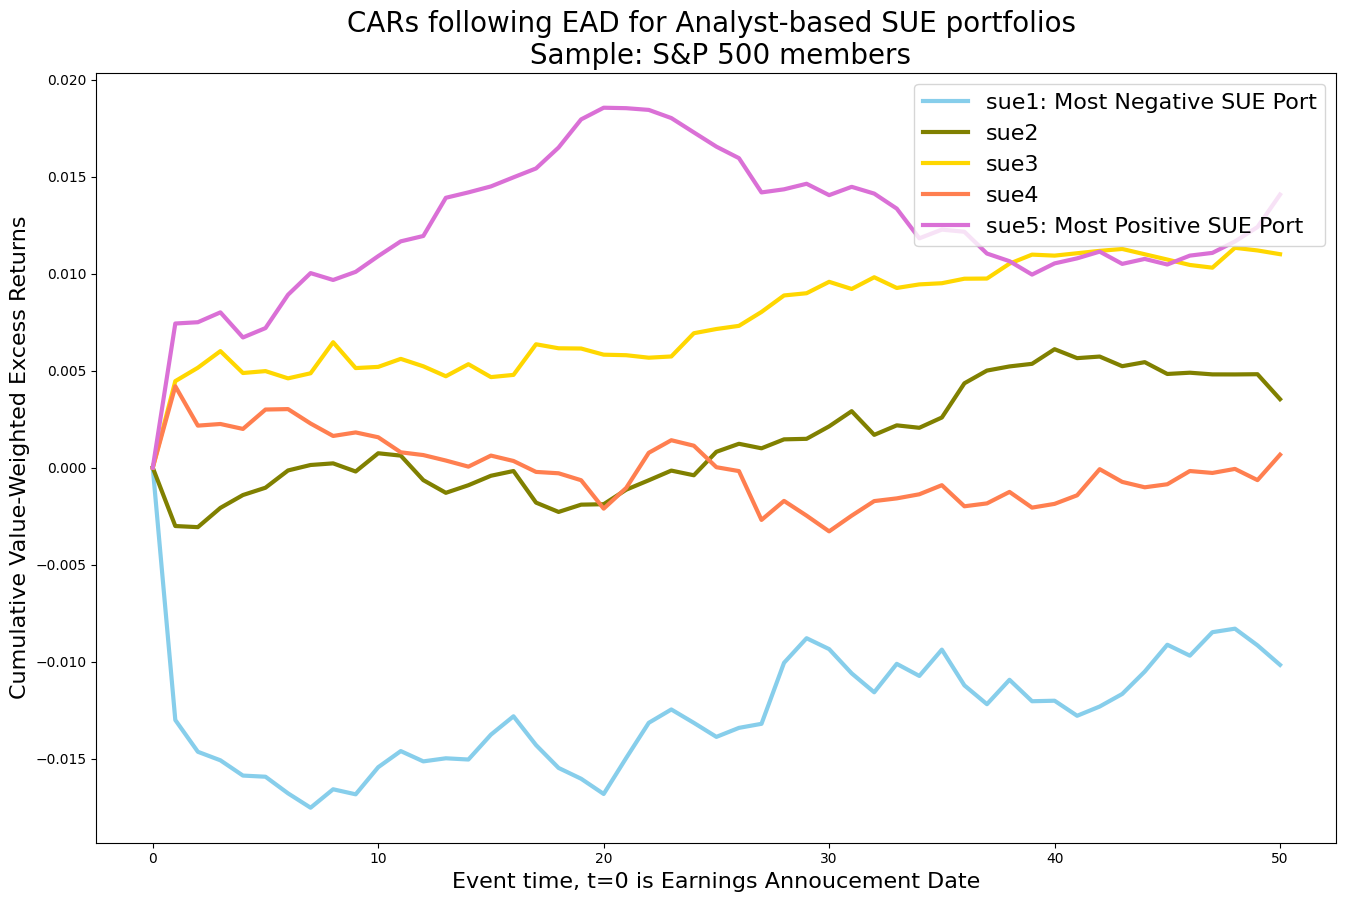

In [21]:
# Plotting the output
import os

# Create plot directory if it doesn't exist
os.makedirs('./plot', exist_ok=True)

import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,10))
plt.title('CARs following EAD for Analyst-based SUE portfolios \n Sample: S&P 500 members', fontsize=20)
plt.xlabel('Event time, t=0 is Earnings Annoucement Date', fontsize=16)
plt.ylabel('Cumulative Value-Weighted Excess Returns', fontsize=16)

plt.plot('ncount', 'sueport1', data=peadsue3port, color='skyblue', linewidth=3, label="sue1: Most Negative SUE Port")
plt.plot('ncount', 'sueport2', data=peadsue3port, color='olive', linewidth=3, label="sue2")
plt.plot('ncount', 'sueport3', data=peadsue3port, color='gold', linewidth=3, label="sue3")
plt.plot('ncount', 'sueport4', data=peadsue3port, color='coral', linewidth=3, label="sue4")
plt.plot('ncount', 'sueport5', data=peadsue3port, color='orchid', linewidth=3, label="sue5: Most Positive SUE Port")

plt.legend(loc="best", fontsize=16)

plt.savefig('./plot/pead_08_18.png')
print("Plot saved to ./plot/pead_08_18.png")

## Step 8: IC, t-stats and IC decay

The portfolio plot shows the drift; the **information coefficient (IC)** measures how well SUE ranks the returns that follow.

- **Monthly event-time IC:** in each calendar month, the Spearman correlation across that month's announcements between SUE and the excess return after the EAD (months with at least 20 announcements).
- **Cumulative (`ic_cum`, k):** return = sum of `exret` over event days 1..k, the CAR in the plot.
- **Single-day (`ic_lag`, k):** return = `exret` on event day k alone, showing *when* the drift happens.
- **t-stats:** mean monthly IC over its Newey–West standard error. A k-day window overlaps into about k/21 later months, so cumulative ICs use ceil(k/21) lags.

**Note:** when a firm announces after the close of `rdq1`, the announcement reaction falls on day 1, so the day-1 IC includes it. Days 2 and later are the drift.

/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/home/charles/.local/lib/python3.10/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide

IC of SUE with CAR over event days 1..k (monthly Spearman, Newey-West t)
    ic_cum                t_cum               hit_cum               months          
sue   sue1   sue2   sue3   sue1   sue2   sue3    sue1   sue2   sue3   sue1 sue2 sue3
k                                                                                   
1    0.056  0.058  0.137  3.455  3.809  8.441   0.787  0.770  0.885     61   61   61
2    0.059  0.057  0.126  3.191  3.122  7.300   0.770  0.738  0.869     61   61   61
5    0.056  0.055  0.113  3.062  2.631  6.215   0.721  0.738  0.836     61   61   61
10   0.059  0.063  0.115  2.946  2.700  6.593   0.689  0.721  0.852     61   61   61
20   0.055  0.056  0.099  2.926  2.749  7.203   0.623  0.689  0.852     61   61   61
50   0.028  0.028  0.071  1.453  1.387  3.611   0.541  0.607  0.754     61   61   61

IC decay for sue3: cumulative (1..k) and single-day (day k)
    ic_cum  t_cum  ic_lag  t_lag
k                               
1    0.137  8.441   0.137  9.114
2 

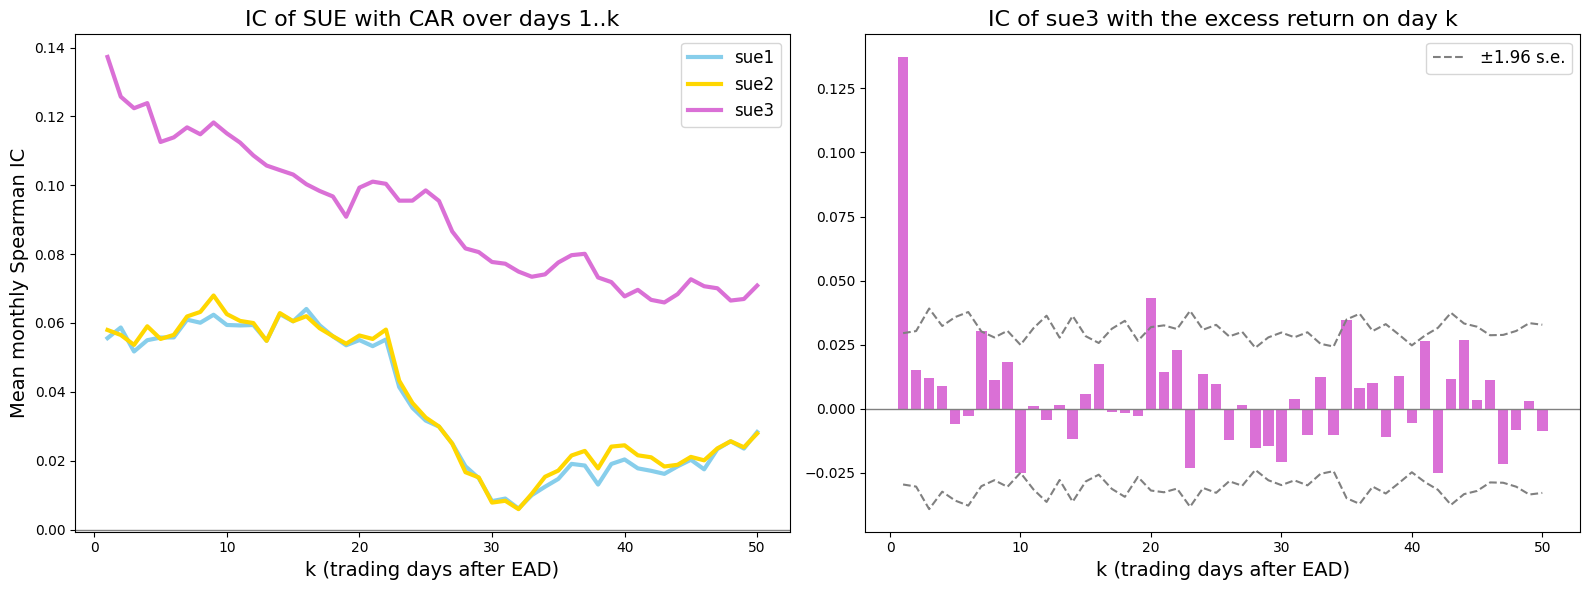

In [22]:
#############################################
# Step 8. IC, t-stats and IC decay of SUE   #
#############################################

# Event-time IC: in each calendar month, the Spearman correlation across the
# announcements made that month (rdq1 in the month) between SUE and the excess
# return after the EAD. Two return windows for event day k:
#   cum k: sum of exret over event days 1..k (the CAR in the plot above)
#   lag k: exret on event day k alone
# The IC is averaged over months; t-stats use Newey-West standard errors. A
# cumulative window of k trading days overlaps the next ~k/21 months, so it uses
# ceil(k/21) lags; single-day ICs use none.
# Note: day 1 contains the announcement reaction when the EA comes after the close of rdq1.

import math
import statsmodels.api as sm

ic_min_names = 20                       # minimum announcements in a month for an IC
ic_days = range(1, 51)                  # event days, as in the plot
ic_horizons = [1, 2, 5, 10, 20, 50]     # rows of the summary table

# one row per announcement (permno, rdq1), one column per event day (0 = rdq1)
events = temp.drop_duplicates(subset=['permno', 'rdq1', 'date']).sort_values(by=['permno', 'rdq1', 'date'])
events['day'] = events.groupby(['permno', 'rdq1']).cumcount()
exret_ev = events.pivot(index=['permno', 'rdq1'], columns='day', values='exret')
sue_ev = events.groupby(['permno', 'rdq1'])[['sue1', 'sue2', 'sue3']].first().reindex(exret_ev.index)
ev_month = exret_ev.index.get_level_values('rdq1').to_period('M')

# CAR over days 1..k; NaN once a day is missing (e.g. after the next EAD)
car_ev = exret_ev.loc[:, 1:].cumsum(axis=1, skipna=False)


def monthly_ic(sue, ret):
    """Spearman IC of sue and ret across each month's announcements."""
    df = pd.DataFrame({'sue': sue.to_numpy(), 'ret': ret.to_numpy(), 'month': ev_month}).dropna()
    df[['sue', 'ret']] = df.groupby('month')[['sue', 'ret']].rank()
    g = df.groupby('month')
    ic = g.apply(lambda d: d.sue.corr(d.ret), include_groups=False)
    return ic[g.size() >= ic_min_names]


def nw_stats(ic, lags):
    """Mean, Newey-West t-stat, hit rate and number of months of an IC series."""
    ic = ic.dropna()
    res = sm.OLS(ic.to_numpy(), np.ones(len(ic))).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return {'ic': res.params[0], 't': res.tvalues[0], 'hit': (ic > 0).mean(), 'months': len(ic)}


rows = []
for s in ['sue1', 'sue2', 'sue3']:
    for k in ic_days:
        cum = nw_stats(monthly_ic(sue_ev[s], car_ev[k]), math.ceil(k / 21))
        lag = nw_stats(monthly_ic(sue_ev[s], exret_ev[k]), 0)
        rows.append({'sue': s, 'k': k,
                     'ic_cum': cum['ic'], 't_cum': cum['t'], 'hit_cum': cum['hit'], 'months': cum['months'],
                     'ic_lag': lag['ic'], 't_lag': lag['t']})
ic_decay = pd.DataFrame(rows).set_index(['sue', 'k'])

# Summary: IC of SUE with the CAR over days 1..k
ic_summary = ic_decay.loc[(slice(None), ic_horizons), ['ic_cum', 't_cum', 'hit_cum', 'months']]
print('IC of SUE with CAR over event days 1..k (monthly Spearman, Newey-West t)')
print(ic_summary.unstack('sue').round(3).to_string())

print('\nIC decay for sue3: cumulative (1..k) and single-day (day k)')
print(ic_decay.loc['sue3', ['ic_cum', 't_cum', 'ic_lag', 't_lag']].loc[ic_horizons].round(3).to_string())

# Plot: cumulative IC by SUE measure, and single-day IC of sue3 with its 95% band
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for s, c in zip(['sue1', 'sue2', 'sue3'], ['skyblue', 'gold', 'orchid']):
    ax1.plot(ic_days, ic_decay.loc[s, 'ic_cum'], color=c, linewidth=3, label=s)
ax1.axhline(0, color='grey', linewidth=1)
ax1.set_title('IC of SUE with CAR over days 1..k', fontsize=16)
ax1.set_xlabel('k (trading days after EAD)', fontsize=14)
ax1.set_ylabel('Mean monthly Spearman IC', fontsize=14)
ax1.legend(fontsize=12)

d3 = ic_decay.loc['sue3']
ax2.bar(ic_days, d3['ic_lag'], color='orchid')
ax2.plot(ic_days, 1.96 * d3['ic_lag'] / d3['t_lag'], color='grey', linestyle='--', label='±1.96 s.e.')
ax2.plot(ic_days, -1.96 * d3['ic_lag'] / d3['t_lag'], color='grey', linestyle='--')
ax2.axhline(0, color='grey', linewidth=1)
ax2.set_title('IC of sue3 with the excess return on day k', fontsize=16)
ax2.set_xlabel('k (trading days after EAD)', fontsize=14)
ax2.legend(fontsize=12)

plt.tight_layout()
plt.savefig('./plot/pead_ic_decay.png')
print("Plot saved to ./plot/pead_ic_decay.png")

## Step 9: Calendar-Time SUE Portfolios and Equity Curves

The event-time plot pools announcements and sorts them on the whole sample. Here the strategy is run **day by day as it could have been traded**:

- **Quintiles:** each announcement gets a `sue3` quintile from breakpoints of the announcements in the **previous 91 days only** (no look-ahead).
- **Holding:** bought at the close of event day 1, held through event day 50 (or the next EAD). Day 1 is skipped because it contains the announcement reaction for after-close announcers.
- **Returns:** value-weighted (market cap at the previous close) excess returns over the CRSP value-weighted index. **Q5-Q1** is long the top quintile, short the bottom.
- **Costs:** `pf_cost_bps` (5) per dollar traded, on the trade from the drifted to the new weights; the long-short pays both legs.

The first plot shows the equity curves at 0 cost, the second net of 5 bps.

In [ ]:
###########################################
# Step 9. Calendar-time SUE portfolios    #
###########################################

# Tradable version of the drift: each announcement is put in a sue3 quintile using
# breakpoints from the announcements of the previous 91 days only (no look-ahead),
# bought at the close of event day pf_first - 1 and held through event day pf_last
# (or the next EAD, where the drift window ends). Day 1 is skipped because it
# contains the announcement reaction for after-close announcers.
# Each day the quintile portfolios are value-weighted (market cap at the previous
# close) and earn excess returns over the CRSP value-weighted index. Costs are
# pf_cost_bps per dollar traded, on the trade from the drifted to the new weights,
# charged the next day; the long-short (Q5 - Q1) pays both legs.

pf_first, pf_last = 2, 50       # event days held
pf_min_past = 50                # minimum past announcements for breakpoints
pf_cost_bps = 5

# sue3 quintile of each announcement from the previous 91 days' breakpoints
ann = sue_ev[['sue3']].dropna().reset_index()
ann['q'] = np.nan
for d, idx in ann.groupby('rdq1').groups.items():
    past = ann.sue3[(ann.rdq1 < d) & (ann.rdq1 >= d - pd.Timedelta(days=91))]
    if len(past) >= pf_min_past:
        bp = np.quantile(past, [0.2, 0.4, 0.6, 0.8])
        ann.loc[idx, 'q'] = np.searchsorted(bp, ann.sue3[idx], side='right') + 1

# Positions held at the close of each day: event days pf_first - 1 .. pf_last - 1
held = events.loc[events.day.between(pf_first - 1, pf_last - 1), ['permno', 'rdq1', 'date']]
held = held.merge(ann[['permno', 'rdq1', 'q']].dropna(), on=['permno', 'rdq1'])
held = held.drop_duplicates(subset=['date', 'permno'])

# date x permno matrices on the CRSP calendar
pf_permnos = held.permno.unique()
ds_pf = ds.loc[ds.permno.isin(pf_permnos)].drop_duplicates(subset=['date', 'permno'])
R = ds_pf.pivot(index='date', columns='permno', values='exret')
cap = ds_pf.pivot(index='date', columns='permno', values='mcap').reindex_like(R)
Q = held.pivot(index='date', columns='permno', values='q').reindex_like(R)

Rv = R.to_numpy()
valid = ~np.isnan(Rv)
Rz = np.where(valid, Rv, 0.0)
gross, traded = {}, {}
for j in range(1, 6):
    base = np.where(Q.to_numpy() == j, np.nan_to_num(cap.to_numpy()), 0.0)
    tot = base.sum(1, keepdims=True)
    W = np.divide(base, tot, out=np.zeros_like(base), where=tot > 0)      # weights at the close of t
    Wp = np.vstack([np.zeros((1, W.shape[1])), W[:-1]])                   # held during t
    Wv = np.where(valid, Wp, 0.0)
    wsum = Wv.sum(1)
    r = np.divide((Wv * Rz).sum(1), wsum, out=np.full(len(wsum), np.nan), where=wsum > 0)
    drift = Wp * (1 + Rz) / (1 + np.nan_to_num(r))[:, None]               # weights after t's returns
    trade = np.abs(W - drift).sum(1)                                      # sum |dW| at the close of t
    gross[f'Q{j}'] = r
    traded[f'Q{j}'] = np.concatenate([[np.nan], trade[:-1]])              # charged on t + 1

pf_gross = pd.DataFrame(gross, index=R.index).dropna(how='all')
pf_trade = pd.DataFrame(traded, index=R.index).reindex(pf_gross.index)
pf_gross['Q5-Q1'] = pf_gross.Q5 - pf_gross.Q1
pf_trade['Q5-Q1'] = pf_trade.Q5 + pf_trade.Q1
pf_net = pf_gross - pf_cost_bps * 1e-4 * pf_trade


def pf_stats(rets):
    """Annualized mean, volatility and Sharpe ratio of daily returns."""
    return pd.DataFrame({'mean_ann': rets.mean() * 252, 'vol_ann': rets.std() * np.sqrt(252),
                         'sharpe': rets.mean() / rets.std() * np.sqrt(252)})


pf_table = pd.concat({'gross': pf_stats(pf_gross), f'net {pf_cost_bps} bps': pf_stats(pf_net)}, axis=1)
pf_table['turnover'] = 0.5 * pf_trade.mean()      # one-way, per day
print(f'SUE quintile portfolios, event days {pf_first}..{pf_last}, value-weighted excess returns')
print(pf_table.round(3).to_string())

In [ ]:
# Equity curves (growth of $1): gross, then net of costs
pf_colors = {'Q1': 'skyblue', 'Q2': 'olive', 'Q3': 'gold', 'Q4': 'coral', 'Q5': 'orchid', 'Q5-Q1': 'black'}
for rets, label, fname in [(pf_gross, '0 bps cost', 'pead_equity_0bps.png'),
                           (pf_net, f'{pf_cost_bps} bps cost', f'pead_equity_{pf_cost_bps}bps.png')]:
    plt.figure(figsize=(16, 10))
    for c in rets.columns:
        plt.plot((1 + rets[c].fillna(0)).cumprod(), color=pf_colors[c], linewidth=3,
                 linestyle='--' if c == 'Q5-Q1' else '-', label=c)
    plt.axhline(1, color='grey', linewidth=1)
    plt.title(f'SUE quintile portfolios, {label}\n Value-weighted excess returns, event days '
              f'{pf_first}..{pf_last}, S&P 500 members', fontsize=20)
    plt.xlabel('Date', fontsize=16)
    plt.ylabel('Growth of $1', fontsize=16)
    plt.legend(loc='best', fontsize=16)
    plt.savefig(f'./plot/{fname}')
    print(f'Plot saved to ./plot/{fname}')